# Day 24 | Turn Replies Into Checked Data

**KGP Talkie**

Compare plain text, JSON, Pydantic schemas, and list parsing.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

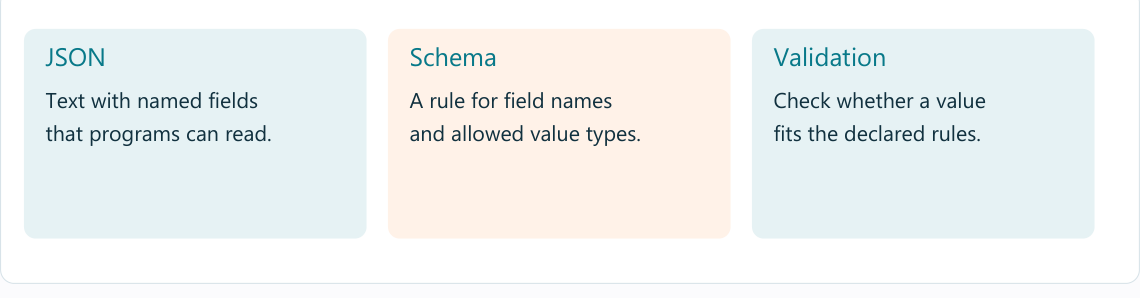

A Pydantic class declares data fields. It is a schema for the output, not a neural network layer.

In [4]:
from pydantic import BaseModel, Field, ValidationError
from langchain_core.output_parsers import JsonOutputParser, PydanticOutputParser

course is text. room is an integer greater than or equal to 1, because our sample rooms have positive numbers.

In [5]:
class Notice(BaseModel):
    course: str = Field(description="The exact course name in the notice")
    room: int = Field(ge=1, description="The room number in the notice")

In [6]:
json_parser = JsonOutputParser()
json_parser.invoke('{"course": "Python", "room": 2}')

{'course': 'Python', 'room': 2}

In [7]:
parser = PydanticOutputParser(pydantic_object=Notice)
parser.invoke('{"course": "Python", "room": 2}')

Notice(course='Python', room=2)

This is one deliberate format failure. We catch it to display the failed validation rather than stop the lesson.

In [8]:
try:
    Notice.model_validate({"course": "Python", "room": "blue"})
except ValidationError:
    print("Rejected: room needs a valid integer.")

Rejected: room needs a valid integer.


ChatOllama sends chat requests to the local Ollama server.

In [9]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [10]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 256-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [11]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=256, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

The model receives the schema. Python still validates the result.

In [12]:
structured = llm.with_structured_output(Notice, method="json_schema")

In [13]:
result = structured.invoke("Extract the notice: Python class is in Room 2.")
result.model_dump()

{'course': 'Python', 'room': 2}

In [14]:
fresh = structured.invoke("Extract the notice: Pandas class is in Room 3.")
fresh.model_dump()

{'course': 'Pandas', 'room': 3}

In [15]:
from langchain_core.output_parsers import CommaSeparatedListOutputParser

A comma list is useful for simple items. JSON is clearer when we need named fields.

In [16]:
CommaSeparatedListOutputParser().invoke("Python, Pandas, Seaborn")

['Python', 'Pandas', 'Seaborn']

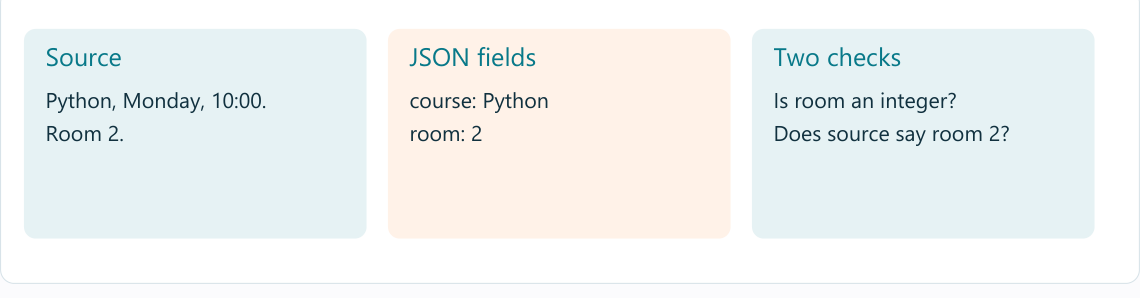

## Try a fresh input

Extract a fresh notice and compare every field with the source. Missing facts should stay missing.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-output-parsing).